In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/gradcam_metrics_by_abnormality.csv
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/gradcam_metrics_by_outcome.csv
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/gradcam_roi_metrics.csv
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/gradcam_summary.json
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/FN_P_00014_LEFT_CC.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/FN_P_00014_LEFT_MLO.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/FP_P_00531_RIGHT_MLO.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/FP_P_01447_RIGHT_CC.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/TN_P_01755_RIGHT_MLO.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/TN_P_01773_RIGHT_MLO.png
/kaggle/input/datasets/ishaans23/classifier-gradcam-artifact/figures/TP_P_00023_RIGHT

In [2]:
from pathlib import Path
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    resnet50,
    ResNet50_Weights,
)

In [3]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

SEGMENTATION_THRESHOLD = 0.90

OUTPUT_DIR = Path(
    "/kaggle/working/end_to_end_inference"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cuda:0


In [4]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)


# ============================================================
# DATASET
# ============================================================

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):

    candidate_root = (
        cache_info_path.parent
    )

    required = [
        candidate_root / "npy",
        candidate_root / "masks",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required
    ):
        dataset_candidates.append(
            candidate_root
        )


assert len(dataset_candidates) > 0

PROJECT_ROOT = sorted(
    dataset_candidates,
    key=lambda path: len(
        str(path)
    ),
)[0]


# ============================================================
# CLASSIFIER
# ============================================================

classifier_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "resnet50_layer4_best.pth"
    )
)

assert len(classifier_candidates) > 0

CLASSIFIER_CHECKPOINT_PATH = (
    classifier_candidates[0]
)


# ============================================================
# SEGMENTATION
# ============================================================

segmentation_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "resnet50_unet_layer4_best.pth"
    )
)

assert len(segmentation_candidates) > 0

SEGMENTATION_CHECKPOINT_PATH = (
    segmentation_candidates[0]
)


print("Dataset:")
print(PROJECT_ROOT)

print("\nClassifier:")
print(CLASSIFIER_CHECKPOINT_PATH)

print("\nSegmentation:")
print(SEGMENTATION_CHECKPOINT_PATH)

Dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training

Classifier:
/kaggle/input/datasets/ishaans23/final-classifier-artifact/resnet50_layer4_best.pth

Segmentation:
/kaggle/input/datasets/ishaans23/resnet50-unet-training-artifact/resnet50_unet_layer4_best.pth


In [5]:
resnet_weights = (
    ResNet50_Weights.DEFAULT
)

weight_transforms = (
    resnet_weights.transforms()
)

NORMALIZATION_MEAN = (
    weight_transforms.mean
)

NORMALIZATION_STD = (
    weight_transforms.std
)


MEAN_TENSOR = torch.tensor(
    NORMALIZATION_MEAN,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)

STD_TENSOR = torch.tensor(
    NORMALIZATION_STD,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


print("Mean:", NORMALIZATION_MEAN)
print("Std:", NORMALIZATION_STD)

Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]


In [6]:
classifier = resnet50(
    weights=None
)

classifier.fc = nn.Linear(
    classifier.fc.in_features,
    1,
)


classifier_checkpoint = torch.load(
    CLASSIFIER_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


classifier.load_state_dict(
    classifier_checkpoint[
        "model_state_dict"
    ]
)


classifier = classifier.to(
    device
)

classifier.eval()


print(
    "Classifier loaded from epoch:",
    classifier_checkpoint["epoch"]
)

Classifier loaded from epoch: 3


In [7]:
class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
    ):

        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2,
        )

        self.conv = nn.Sequential(

            nn.Conv2d(
                out_channels
                + skip_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            nn.GroupNorm(
                8,
                out_channels,
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            nn.GroupNorm(
                8,
                out_channels,
            ),

            nn.ReLU(
                inplace=True
            ),
        )


    def forward(
        self,
        x,
        skip,
    ):

        x = self.up(x)

        x = torch.cat(
            [
                x,
                skip,
            ],
            dim=1,
        )

        return self.conv(x)

In [8]:
class ResNet50UNet(nn.Module):

    def __init__(
        self,
        backbone,
    ):

        super().__init__()

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.up4 = DecoderBlock(
            2048,
            1024,
            512,
        )

        self.up3 = DecoderBlock(
            512,
            512,
            256,
        )

        self.up2 = DecoderBlock(
            256,
            256,
            128,
        )

        self.up1 = DecoderBlock(
            128,
            64,
            64,
        )

        self.final_up = nn.Sequential(

            nn.ConvTranspose2d(
                64,
                32,
                kernel_size=2,
                stride=2,
            ),

            nn.GroupNorm(
                8,
                32,
            ),

            nn.ReLU(
                inplace=True
            ),
        )

        self.output = nn.Conv2d(
            32,
            1,
            kernel_size=1,
        )


    def forward(
        self,
        x,
    ):

        e0 = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        x = self.maxpool(e0)

        e1 = self.layer1(x)
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)

        d4 = self.up4(
            e4,
            e3,
        )

        d3 = self.up3(
            d4,
            e2,
        )

        d2 = self.up2(
            d3,
            e1,
        )

        d1 = self.up1(
            d2,
            e0,
        )

        x = self.final_up(d1)

        return self.output(x)

In [9]:
segmentation_backbone = (
    resnet50(
        weights=None
    )
)

segmentation_model = (
    ResNet50UNet(
        backbone=
            segmentation_backbone
    )
)


segmentation_checkpoint = torch.load(
    SEGMENTATION_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


segmentation_model.load_state_dict(
    segmentation_checkpoint[
        "model_state_dict"
    ]
)


segmentation_model = (
    segmentation_model.to(
        device
    )
)

segmentation_model.eval()


print(
    "Segmentation checkpoint stage:",
    segmentation_checkpoint[
        "stage"
    ]
)

print(
    "Segmentation epoch:",
    segmentation_checkpoint[
        "epoch"
    ]
)

Segmentation checkpoint stage: layer4_finetune
Segmentation epoch: 3


In [10]:
def prepare_image(
    image,
):

    assert image.shape == (
        TARGET_HEIGHT,
        TARGET_WIDTH,
    )


    image_float = (
        image.astype(
            np.float32
        )
        / 65535.0
    )


    tensor = torch.from_numpy(
        image_float
    ).to(
        device
    )


    tensor = (
        tensor
        .unsqueeze(0)
        .unsqueeze(0)
        .repeat(
            1,
            3,
            1,
            1,
        )
    )


    tensor = (
        tensor
        - MEAN_TENSOR
    ) / STD_TENSOR


    return tensor

In [32]:
class GradCAM:

    def __init__(
        self,
        model,
        target_layer,
    ):

        self.model = model
        self.target_layer = target_layer


    def generate(
        self,
        input_tensor,
        predicted_label,
    ):

        activations = None
        gradients = None


        def forward_hook(
            module,
            inputs,
            output,
        ):

            nonlocal activations
            nonlocal gradients

            activations = output


            def save_gradient(
                gradient,
            ):

                nonlocal gradients

                gradients = gradient


            output.register_hook(
                save_gradient
            )


        # Hook exists ONLY during this Grad-CAM call.
        handle = (
            self.target_layer
            .register_forward_hook(
                forward_hook
            )
        )


        try:

            self.model.zero_grad(
                set_to_none=True
            )


            with torch.enable_grad():

                logit = self.model(
                    input_tensor
                ).squeeze()


                if int(
                    predicted_label
                ) == 1:

                    target_score = (
                        logit
                    )

                else:

                    target_score = (
                        -logit
                    )


                target_score.backward()


            assert (
                activations
                is not None
            ), (
                "Grad-CAM activations "
                "were not captured."
            )


            assert (
                gradients
                is not None
            ), (
                "Grad-CAM gradients "
                "were not captured."
            )


            weights = (
                gradients.mean(
                    dim=(2, 3),
                    keepdim=True,
                )
            )


            cam = (
                weights
                * activations
            ).sum(
                dim=1,
                keepdim=True,
            )


            cam = F.relu(
                cam
            )


            cam = F.interpolate(
                cam,
                size=(
                    TARGET_HEIGHT,
                    TARGET_WIDTH,
                ),
                mode="bilinear",
                align_corners=False,
            )


            cam = cam[
                0,
                0,
            ]


            cam_min = (
                cam.min()
            )

            cam_max = (
                cam.max()
            )


            cam = (
                cam
                - cam_min
            ) / (
                cam_max
                - cam_min
                + 1e-8
            )


            return (
                cam.detach()
                .cpu()
                .numpy()
            )


        finally:

            # Critical:
            # remove the hook immediately.
            handle.remove()

In [33]:
# ============================================================
# REBUILD CLEAN CLASSIFIER
# Removes all previously attached Grad-CAM hooks
# ============================================================

classifier = resnet50(
    weights=None
)

classifier.fc = nn.Linear(
    classifier.fc.in_features,
    1,
)


classifier_checkpoint = torch.load(
    CLASSIFIER_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


classifier.load_state_dict(
    classifier_checkpoint[
        "model_state_dict"
    ]
)


classifier = classifier.to(
    device
)

classifier.eval()


print(
    "Fresh classifier loaded."
)

print(
    "Epoch:",
    classifier_checkpoint[
        "epoch"
    ]
)

Fresh classifier loaded.
Epoch: 3


In [34]:
gradcam = GradCAM(
    classifier,
    classifier.layer4[-1],
)


def run_inference(
    image,
):

    input_tensor = (
        prepare_image(
            image
        )
    )


    # ========================================================
    # CLASSIFICATION
    # ========================================================

    with torch.inference_mode():

        classification_logit = (
            classifier(
                input_tensor
            ).squeeze()
        )

        malignancy_probability = (
            torch.sigmoid(
                classification_logit
            ).item()
        )


    predicted_label = int(
        malignancy_probability
        >= 0.2915
    )


    # ========================================================
    # SEGMENTATION
    # ========================================================

    with torch.inference_mode():

        segmentation_logits = (
            segmentation_model(
                input_tensor
            )
        )

        segmentation_probability = (
            torch.sigmoid(
                segmentation_logits
            )
        )


    segmentation_mask = (
        segmentation_probability[
            0,
            0,
        ]
        >= SEGMENTATION_THRESHOLD
    ).cpu().numpy()


    # ========================================================
    # GRAD-CAM
    # ========================================================

    # Grad-CAM requires gradients, so use a fresh
    # tensor outside inference_mode.
    gradcam_input = (
        input_tensor
        .detach()
        .clone()
        .requires_grad_(
            True
        )
    )


    with torch.enable_grad():

        cam = gradcam.generate(
            input_tensor=
                gradcam_input,

            predicted_label=
                predicted_label,
        )


    return {
        "malignancy_probability":
            float(
                malignancy_probability
            ),

        "predicted_label":
            predicted_label,

        "predicted_class":
            (
                "malignant"
                if predicted_label == 1
                else "non-malignant"
            ),

        "segmentation_mask":
            segmentation_mask,

        "segmentation_probability":
            segmentation_probability[
                0,
                0,
            ]
            .cpu()
            .numpy(),

        "gradcam":
            cam,
    }

In [37]:
test_df = pd.read_csv(
    PROJECT_ROOT
    / "splits"
    / "test.csv"
)


example_row = (
    test_df.sample(
        n=1,
        random_state=SEED,
    )
    .iloc[0]
)


example_image = np.load(
    PROJECT_ROOT
    / example_row[
        "npy_path"
    ]
)


print(
    "Example:",
    example_row[
        "image_key"
    ]
)

print(
    "Ground truth pathology:",
    example_row[
        "pathology"
    ]
)

print(
    "Abnormality:",
    example_row[
        "abnormality_type"
    ]
)

Example: P_00408_RIGHT_CC
Ground truth pathology: MALIGNANT
Abnormality: mass


In [38]:
result = run_inference(
    example_image
)


print(
    "Malignancy probability:",
    f"{result['malignancy_probability']:.4f}"
)

print(
    "Predicted class:",
    result[
        "predicted_class"
    ]
)

print(
    "Predicted lesion pixels:",
    int(
        result[
            "segmentation_mask"
        ].sum()
    )
)

Malignancy probability: 0.2126
Predicted class: non-malignant
Predicted lesion pixels: 4526


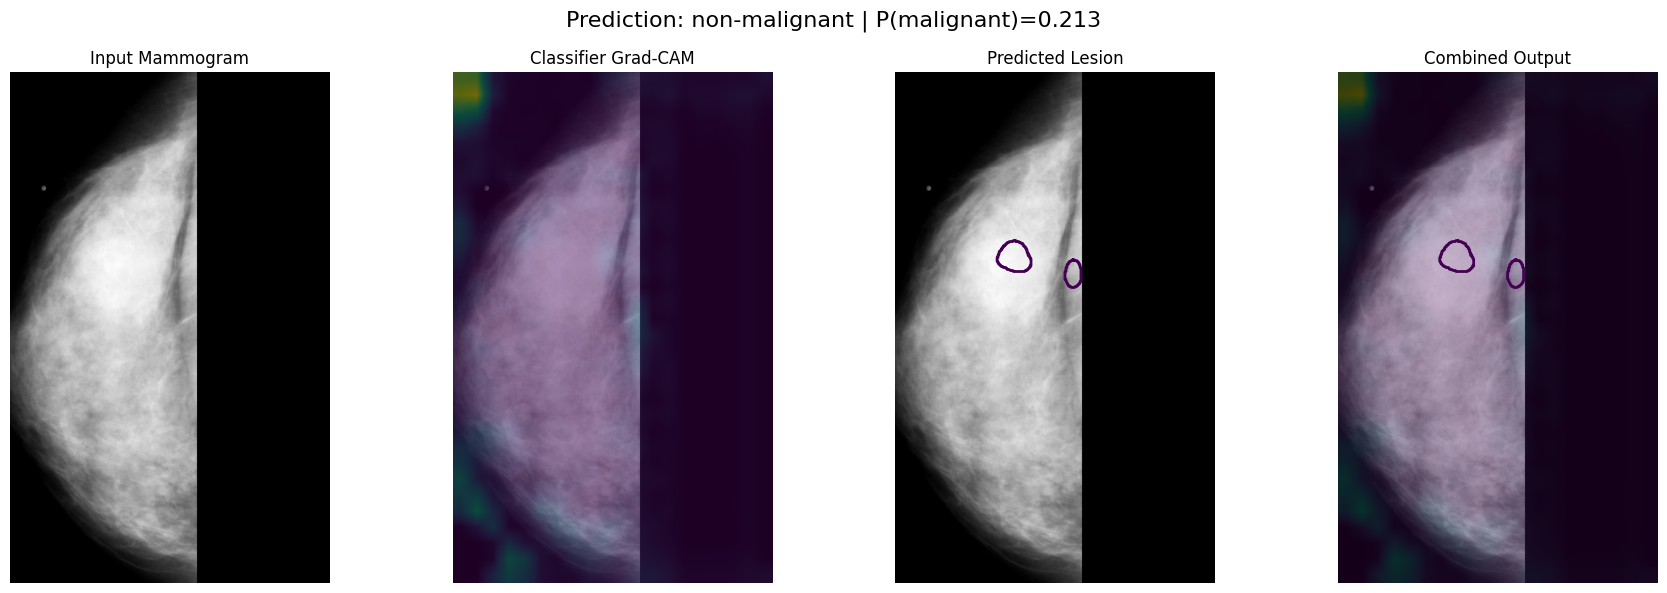

Saved: /kaggle/working/end_to_end_inference/end_to_end_example.png


In [39]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(
        18,
        6,
    ),
)


# ============================================================
# MAMMOGRAM
# ============================================================

axes[0].imshow(
    example_image,
    cmap="gray",
)

axes[0].set_title(
    "Input Mammogram"
)


# ============================================================
# GRAD-CAM
# ============================================================

axes[1].imshow(
    example_image,
    cmap="gray",
)

axes[1].imshow(
    result[
        "gradcam"
    ],
    alpha=0.45,
)

axes[1].set_title(
    "Classifier Grad-CAM"
)


# ============================================================
# SEGMENTATION
# ============================================================

axes[2].imshow(
    example_image,
    cmap="gray",
)

axes[2].contour(
    result[
        "segmentation_mask"
    ],
    levels=[0.5],
    linewidths=2,
)

axes[2].set_title(
    "Predicted Lesion"
)


# ============================================================
# COMBINED
# ============================================================

axes[3].imshow(
    example_image,
    cmap="gray",
)

axes[3].imshow(
    result[
        "gradcam"
    ],
    alpha=0.30,
)

axes[3].contour(
    result[
        "segmentation_mask"
    ],
    levels=[0.5],
    linewidths=2,
)

axes[3].set_title(
    "Combined Output"
)


for ax in axes:
    ax.axis(
        "off"
    )


fig.suptitle(
    (
        f"Prediction: "
        f"{result['predicted_class']} | "
        f"P(malignant)="
        f"{result['malignancy_probability']:.3f}"
    ),
    fontsize=16,
)


plt.tight_layout()


FINAL_FIGURE_PATH = (
    OUTPUT_DIR
    / "end_to_end_example.png"
)


plt.savefig(
    FINAL_FIGURE_PATH,
    dpi=180,
    bbox_inches="tight",
)


plt.show()


print(
    "Saved:",
    FINAL_FIGURE_PATH
)

In [40]:
from pathlib import Path
import json
import shutil


ARTIFACT_DIR = Path(
    "/kaggle/working/"
    "end_to_end_inference_artifact"
)

if ARTIFACT_DIR.exists():
    shutil.rmtree(
        ARTIFACT_DIR
    )

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# Copy final visualization
shutil.copy2(
    FINAL_FIGURE_PATH,
    ARTIFACT_DIR
    / "end_to_end_example.png",
)


# Save compact inference summary
inference_summary = {

    "classifier_checkpoint":
        CLASSIFIER_CHECKPOINT_PATH.name,

    "segmentation_checkpoint":
        SEGMENTATION_CHECKPOINT_PATH.name,

    "classifier_threshold":
        0.2915,

    "segmentation_threshold":
        SEGMENTATION_THRESHOLD,

    "input_resolution": [
        TARGET_HEIGHT,
        TARGET_WIDTH,
    ],

    "example_image_key":
        example_row[
            "image_key"
        ],

    "example_ground_truth_pathology":
        example_row[
            "pathology"
        ],

    "example_abnormality_type":
        example_row[
            "abnormality_type"
        ],

    "example_output": {

        "malignancy_probability":
            float(
                result[
                    "malignancy_probability"
                ]
            ),

        "predicted_class":
            result[
                "predicted_class"
            ],

        "predicted_lesion_pixels":
            int(
                result[
                    "segmentation_mask"
                ].sum()
            ),
    },

    "pipeline":
        (
            "High-resolution mammogram "
            "-> ResNet-50 malignancy classifier "
            "-> Grad-CAM explanation "
            "-> ResNet50-U-Net lesion segmentation "
            "-> combined visualization"
        ),
}


with open(
    ARTIFACT_DIR
    / "inference_summary.json",
    "w",
) as f:

    json.dump(
        inference_summary,
        f,
        indent=2,
    )


zip_path = shutil.make_archive(
    "/kaggle/working/"
    "end_to_end_inference_artifact",
    "zip",
    ARTIFACT_DIR,
)


print("ZIP created:")
print(zip_path)

ZIP created:
/kaggle/working/end_to_end_inference_artifact.zip
